
## Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders

### Baselines

This notebook is a wrapper around `scripts/baselines.py`. The logic lives in the script, so the same code runs from the command line (`python scripts/baselines.py`) and from here. 

**Baselines**
- **Majority class:** predicts the most frequent intent of the training subset for every example. On the balanced test set this equals chance (1/77), so it is the floor of the learning curves.

- **TF-IDF + logistic regression:** TF-IDF features into a logistic regression, trained on each training subset. scikit-learn defaults for both parts, with no hyperparameter tuning. The only change is `max_iter=1000`, so the solver can finish. A check of `C` may be added later.

**Output:** one prediction CSV per run and split in `results/`, following `results/PREDICTION_FORMAT.md` (budgets k1 to k30, p50 and full; seeds 0, 1, 2; splits val and test).

#### Setup

In [21]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

# Find the project root (the folder that contains scripts/download_data.py), wherever the kernel starts
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "scripts" / "download_data.py").exists()), cwd)

# Make scripts/ importable, then load the baseline code (nothing runs on import)
sys.path.insert(0, str(ROOT / "scripts"))
import baselines
import evaluation as ev

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# ---- Settings ----
SPLITS = ["val", "test"]       # Which splits to write predictions for
RUN_BASELINES = True           # Set to False to only look at results that are already in results/
BASELINES = ["majority", "tfidf_lr"]

def natural_order(summary):
    # For display only: sort by model, then by budget size (k1, k3, ..., full) instead of alphabetically
    order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
    out = summary.copy()
    out["budget"] = pd.Categorical(out["budget"], categories=order, ordered=True)
    return out.sort_values(["model", "budget"]).reset_index(drop=True)

print("Project root:", ROOT)
print("Run baselines:", RUN_BASELINES, "| Splits:", SPLITS)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder
Run baselines: True | Splits: ['val', 'test']


#### Majority class
For every budget and seed, the most frequent intent of the training subset is predicted for every example. On the balanced subsets (k1 to k30) all 77 intents tie, and the tie goes to the smallest label id. Accuracy should be 1/77 (about 1.3%) at every budget.

In [14]:
# Writes 8 budgets x 3 seeds x 2 splits = 48 files (safe to re-run: files are overwritten with identical content)
if RUN_BASELINES:
    baselines.run_majority(SPLITS)

Majority: prediction files written: 48 | Folder: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/results


#### TF-IDF + logistic regression
The model that is trained for every run:

In [15]:
# The pipeline: scikit-learn defaults for both parts, except max_iter=1000
baselines.make_tfidf_lr()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


Each run fits on one training subset and predicts the validation and test texts. The full training set is the same file for every seed, so it is fitted only once. Expect a harmless scikit-learn warning at k1 (77 classes for 77 examples).

In [ ]:

if RUN_BASELINES:
    baselines.run_tfidf_lr(SPLITS)

/Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
/Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  check_classification_targets(y)
/Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1447: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y

Finished budget: k1
Finished budget: k3
Finished budget: k5
Finished budget: k10
Finished budget: k20
Finished budget: k30
Finished budget: p50
Finished budget: full
TF-IDF + LR: prediction files written: 48 | Folder: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/results
Loss file written: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/results/diagnostics/tfidf_lr_loss_by_budget.csv


#### Validation scores
Validation scores for the baselines. 

In [17]:
val_scores = ev.score_all("val")
val_summary = ev.summarize(val_scores[val_scores["model"].isin(BASELINES)])
natural_order(val_summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,tfidf_lr,baseline,k1,0.284,0.004,0.265,0.003,3
9,tfidf_lr,baseline,k3,0.483,0.018,0.461,0.016,3


#### Test scores
Mean and standard deviation over the three seeds. The majority baseline has a standard deviation of 0, because its prediction does not depend on the seed. TF-IDF at `full` also has 0, because the same data is fitted for every seed.

In [18]:
# Score every test file in results/, keep only the baselines
scores = ev.score_all("test")
baseline_scores = scores[scores["model"].isin(BASELINES)]

summary = ev.summarize(baseline_scores)
natural_order(summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,tfidf_lr,baseline,k1,0.284,0.028,0.271,0.031,3
9,tfidf_lr,baseline,k3,0.484,0.012,0.473,0.012,3


### Learning curve
Accuracy against the number of training examples (log scale). The figure is saved to `reports/figures/`.

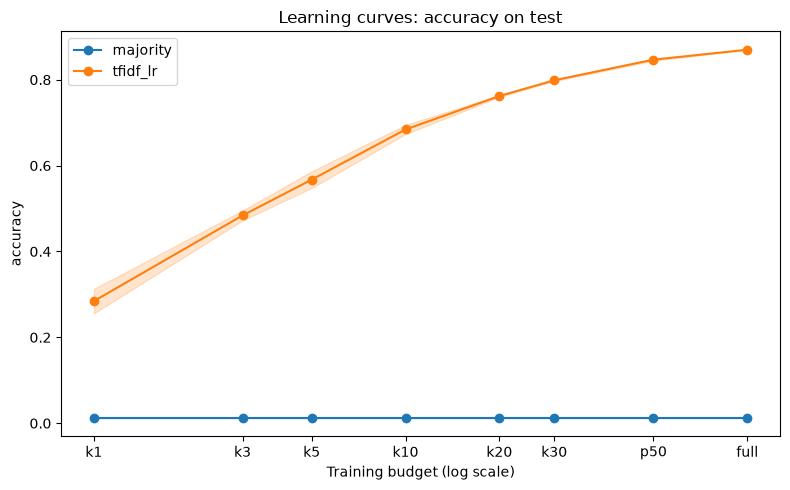

In [19]:
ev.plot_learning_curve(summary, "accuracy", save_to=FIG / "baselines_accuracy.png")

### Loss vs. training size (TF-IDF)
Log-loss is the average of -ln(probability given to the correct intent). Lower is better, and guessing all 77 intents equally gives ln 77 = 4.34. Train loss is measured on the training subset, validation loss on the validation set. A large gap means overfitting. Both staying high means the model is under-confident, which can happen with the default regularization (`C=1`).

,budget,n_train,train_loss_mean,train_loss_std,val_loss_mean,val_loss_std,gap
0,k1,77.0,3.433,0.004,4.171,0.003,0.737
1,k3,231.0,3.172,0.026,3.881,0.012,0.709
2,k5,385.0,2.935,0.027,3.619,0.022,0.684
3,k10,770.0,2.489,0.019,3.074,0.023,0.585
4,k20,1540.0,1.924,0.019,2.409,0.017,0.484
5,k30,2310.0,1.610,0.006,2.016,0.007,0.406
6,p50,4807.0,1.144,0.005,1.438,0.017,0.293
7,full,9618.0,0.827,0.000,1.066,0.000,0.239


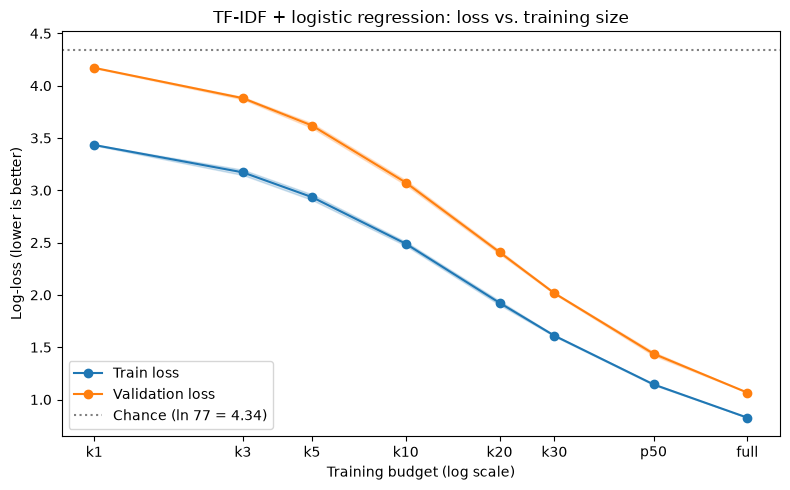

In [20]:
import diagnostics as dg

# Mean and standard deviation over seeds for each budget; gap = validation loss minus train loss
display(dg.summarize_tfidf_loss().round(3))

# Train and validation loss against the number of training examples
dg.plot_tfidf_loss_vs_budget(save_to=FIG / "tfidf_loss_vs_budget.png")

##### The default-regularized TF-IDF model is under-confident: even its training log-loss at the full budget is 0.83.